# AWS ML Task - Week 03: Breaking the SMS Spam Filter

---


## 1. Environment Setup & Library Imports

We import essential scientific, machine learning, and visualization libraries:
- **`numpy`**: High-performance vectorized numerical operations and array transformations.
- **`pandas`**: Tabular data manipulation, ingestion, and dataframe operations.
- **`sklearn`**: TF-IDF feature extraction, Multinomial Naive Bayes classifier, train-test splitting, and evaluation metrics.
- **`matplotlib` & `seaborn`**: Statistical visualizations and confusion matrix heatmaps.


In [19]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("Core libraries successfully imported.")


Core libraries successfully imported.


## 2. Raw Dataset Ingestion

We load the standard **SMS Spam Collection** dataset. 


In [21]:
DATA_URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
CANDIDATE_PATHS = [
    "data/sms.tsv",
    "week-03/data/sms.tsv",
    "../week-03/data/sms.tsv",
    os.path.join(os.path.dirname(os.path.abspath(__file__)), "data/sms.tsv") if '__file__' in locals() else "data/sms.tsv"
]

def load_raw_data(candidate_paths=CANDIDATE_PATHS, fallback_url=DATA_URL) -> pd.DataFrame:
    """
    Loads raw SMS spam dataset from local candidate paths or falls back to remote URL.
    """
    local_path = None
    for p in candidate_paths:
        if os.path.exists(p):
            local_path = p
            break

    if local_path:
        print(f"[INFO] Loading raw dataset from local repository: '{local_path}'")
        df = pd.read_csv(local_path, sep='\t', header=None, names=['label', 'message'])
    else:
        print(f"[INFO] Local dataset not detected. Fetching from remote URL: {fallback_url}")
        df = pd.read_csv(fallback_url, sep='\t', header=None, names=['label', 'message'])
        os.makedirs("data", exist_ok=True)
        try:
            df.to_csv("data/sms.tsv", sep='\t', header=False, index=False)
            print("[INFO] Cached dataset locally at 'data/sms.tsv'")
        except Exception:
            pass

    print(f"Raw dataset shape: {df.shape[0]} rows, {df.shape[1]} columns.")
    return df

df_raw = load_raw_data()
df_raw.head(5)


[INFO] Loading raw dataset from local repository: 'data/sms.tsv'
Raw dataset shape: 5572 rows, 2 columns.


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Data Cleaning Pipeline

1. `clean_missing_and_duplicates`: Detects and removes nulls and duplicate messages.
2. `clean_text_fields`: Normalizes whitespace, strips non-printable characters, and fixes casing.
3. `convert_data_types`: Enforces explicit data types (`string`, `category`, and integer length metrics).
4. `detect_text_outliers`: Employs the Interquartile Range (IQR) technique and NumPy to flag character length anomalies.


In [23]:
def clean_missing_and_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    """
    Detects and handles missing values and duplicate records.
    """
    df_clean = df.copy()
    initial_len = len(df_clean)

    # 1. Missing values
    null_counts = df_clean.isna().sum().to_dict()
    print(f"[CLEAN] Missing values detected per column: {null_counts}")
    df_clean = df_clean.dropna(subset=['label', 'message'])

    # 2. Duplicate records
    dup_count = df_clean.duplicated(subset=['message']).sum()
    print(f"[CLEAN] Duplicate messages detected: {dup_count}")
    df_clean = df_clean.drop_duplicates(subset=['message']).reset_index(drop=True)

    print(f"[CLEAN] Deduplication complete: {initial_len} -> {len(df_clean)} records ({dup_count} duplicates removed).")
    return df_clean


def clean_text_fields(df: pd.DataFrame) -> pd.DataFrame:
    """
    Trims extraneous padding, replaces consecutive whitespaces, and standardizes casing.
    """
    df_clean = df.copy()
    df_clean['message'] = df_clean['message'].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)
    df_clean['label'] = df_clean['label'].astype(str).str.strip().str.lower()
    print("[CLEAN] Text whitespace normalization completed.")
    return df_clean


def convert_data_types(df: pd.DataFrame) -> pd.DataFrame:
    """
    Enforces strict column datatypes and computes character and word counts.
    """
    df_clean = df.copy()
    df_clean['message'] = df_clean['message'].astype("string")
    df_clean['label'] = df_clean['label'].astype("category")
    df_clean['char_length'] = df_clean['message'].str.len().astype(np.int64)
    df_clean['word_count'] = df_clean['message'].str.split().str.len().astype(np.int64)
    print(f"[CLEAN] Datatypes converted: message ({df_clean['message'].dtype}), label ({df_clean['label'].dtype}), char_length (int64).")
    return df_clean


def detect_text_outliers(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculates IQR bounds on message lengths and flags extreme length anomalies using NumPy.
    IQR = Q3 - Q1
    Lower = max(0, Q1 - 1.5 * IQR)
    Upper = Q3 + 1.5 * IQR
    """
    df_clean = df.copy()
    lengths = df_clean['char_length'].to_numpy()

    q25, q75 = np.percentile(lengths, [25, 75])
    iqr = q75 - q25
    lower_bound = max(0.0, q25 - 1.5 * iqr)
    upper_bound = q75 + 1.5 * iqr

    df_clean['is_length_outlier'] = np.where(
        (df_clean['char_length'] < lower_bound) | (df_clean['char_length'] > upper_bound),
        True,
        False
    )
    outlier_count = int(np.sum(df_clean['is_length_outlier']))
    print(f"[OUTLIERS] IQR Bounds: [{lower_bound:.1f}, {upper_bound:.1f}] chars | Flagged {outlier_count} outliers.")
    return df_clean


### Executing the Data Cleaning Pipeline

In [24]:
print("--- Stage 1: Missing Values & Deduplication ---")
df_s1 = clean_missing_and_duplicates(df_raw)

print("\n--- Stage 2: Text Normalization ---")
df_s2 = clean_text_fields(df_s1)

print("\n--- Stage 3: Type Conversions & Feature Engineering ---")
df_s3 = convert_data_types(df_s2)

print("\n--- Stage 4: Outlier Detection ---")
df_cleaned = detect_text_outliers(df_s3)

print(f"\nCleaned Dataset Ready: {df_cleaned.shape[0]} rows, {df_cleaned.shape[1]} columns.")
df_cleaned.sample(5, random_state=42)


--- Stage 1: Missing Values & Deduplication ---
[CLEAN] Missing values detected per column: {'label': 0, 'message': 0}
[CLEAN] Duplicate messages detected: 403
[CLEAN] Deduplication complete: 5572 -> 5169 records (403 duplicates removed).

--- Stage 2: Text Normalization ---
[CLEAN] Text whitespace normalization completed.

--- Stage 3: Type Conversions & Feature Engineering ---
[CLEAN] Datatypes converted: message (string), label (category), char_length (int64).

--- Stage 4: Outlier Detection ---
[OUTLIERS] IQR Bounds: [0.0, 241.0] chars | Flagged 65 outliers.

Cleaned Dataset Ready: 5169 rows, 5 columns.


,label,message,char_length,word_count,is_length_outlier
1566,ham,"K, makes sense, btw carlos is being difficult ...",121,25,False
1988,spam,"URGENT! Your mobile No *********** WON a £2,00...",158,26,False
1235,ham,If you still havent collected the dough pls le...,116,26,False
2868,ham,Wat time do u wan 2 meet me later?,34,9,False
3435,spam,"You can stop further club tones by replying ""S...",155,26,False


## 4. NumPy Statistical Computations

Below, we compute vectorized metrics across messages.
1. `np.mean()`: Average character and word count.
2. `np.median()`: 50th percentile central tendency robust against extreme outliers.
3. `np.std()`: Standard deviation quantifying text length volatility.
4. `np.percentile()`: Multi-quantile distribution breakdown (10th, 25th, 50th, 75th, 90th, 99th percentiles).
5. `np.unique()`: Unique class extraction and frequencies.
6. `np.where()`: Conditional binary masking to compute subset statistics for Spam vs Ham.


In [25]:
lengths = df_cleaned['char_length'].to_numpy()
words = df_cleaned['word_count'].to_numpy()
labels = df_cleaned['label'].to_numpy()

# 1. np.mean
mean_char_len = np.mean(lengths)
mean_word_count = np.mean(words)

# 2. np.median
median_char_len = np.median(lengths)
median_word_count = np.median(words)

# 3. np.std
std_char_len = np.std(lengths)
std_word_count = np.std(words)

# 4. np.percentile
p10, p25, p50, p75, p90, p99 = np.percentile(lengths, [10, 25, 50, 75, 90, 99])

# 5. np.unique
classes, counts = np.unique(labels, return_counts=True)
class_distribution = dict(zip(classes, counts))

# 6. np.where (Class-specific conditional slicing)
spam_mask = np.where(labels == 'spam')
ham_mask = np.where(labels == 'ham')
spam_mean_len = np.mean(lengths[spam_mask])
ham_mean_len = np.mean(lengths[ham_mask])
spam_std_len = np.std(lengths[spam_mask])
ham_std_len = np.std(lengths[ham_mask])

print("="*60)
print("NUMPY STATISTICAL COMPUTATION REPORT")
print("="*60)
print(f"Total Observations      : {len(lengths):,}")
print(f"Classes & Frequencies   : {class_distribution}")
print(f"Mean Character Length   : {mean_char_len:.2f} chars (std: {std_char_len:.2f})")
print(f"Median Character Length : {median_char_len:.1f} chars (IQR: [{p25:.1f}, {p75:.1f}])")
print(f"Percentiles [10, 50, 90]: p10={p10:.1f}, p50={p50:.1f}, p90={p90:.1f}, p99={p99:.1f}")
print(f"Mean Word Count         : {mean_word_count:.2f} words (median: {median_word_count:.1f})")
print(f"Spam Mean ± Std Length  : {spam_mean_len:.2f} ± {spam_std_len:.2f} chars")
print(f"Ham Mean ± Std Length   : {ham_mean_len:.2f} ± {ham_std_len:.2f} chars")
print("="*60)


NUMPY STATISTICAL COMPUTATION REPORT
Total Observations      : 5,169
Classes & Frequencies   : {'ham': np.int64(4516), 'spam': np.int64(653)}
Mean Character Length   : 79.23 chars (std: 58.34)
Median Character Length : 61.0 chars (IQR: [36.0, 118.0])
Percentiles [10, 50, 90]: p10=26.0, p50=61.0, p90=155.0, p99=272.0
Mean Word Count         : 15.44 words (median: 12.0)
Spam Mean ± Std Length  : 137.66 ± 29.78 chars
Ham Mean ± Std Length   : 70.78 ± 56.59 chars


## 5. Exploratory Data Visualization

Visualizing the class imbalance and structural differences in length distributions between legitimate (ham) and spam SMS messages.


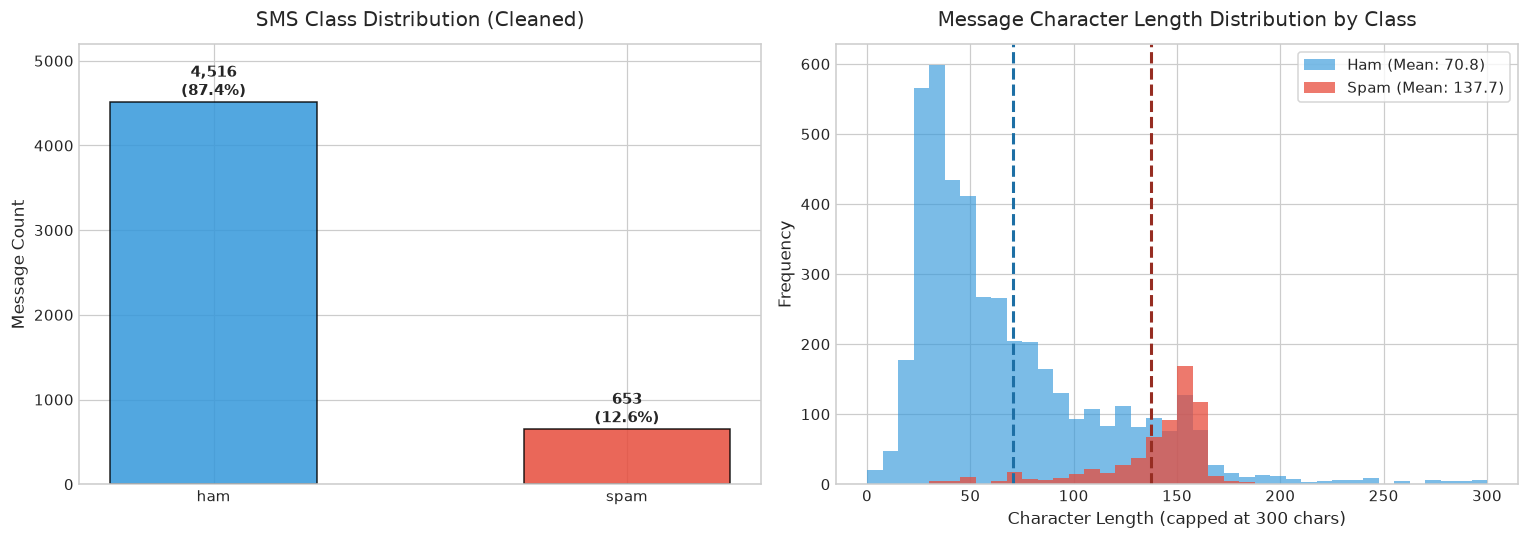

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Class Distribution Bar Chart
colors = ['#3498db', '#e74c3c']
axes[0].bar(classes, counts, color=colors, edgecolor='black', alpha=0.85, width=0.5)
for i, count in enumerate(counts):
    axes[0].text(i, count + 80, f"{count:,}\n({count/len(labels)*100:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title("SMS Class Distribution (Cleaned)", fontsize=13, pad=12)
axes[0].set_ylabel("Message Count", fontsize=11)
axes[0].set_ylim(0, max(counts) * 1.15)

# 2. Character Length Distribution Histogram
axes[1].hist(lengths[ham_mask], bins=40, range=(0, 300), alpha=0.65, color='#3498db', label=f'Ham (Mean: {ham_mean_len:.1f})', edgecolor='none')
axes[1].hist(lengths[spam_mask], bins=40, range=(0, 300), alpha=0.75, color='#e74c3c', label=f'Spam (Mean: {spam_mean_len:.1f})', edgecolor='none')
axes[1].axvline(ham_mean_len, color='#1d6fa5', linestyle='--', linewidth=2)
axes[1].axvline(spam_mean_len, color='#962d22', linestyle='--', linewidth=2)
axes[1].set_title("Message Character Length Distribution by Class", fontsize=13, pad=12)
axes[1].set_xlabel("Character Length (capped at 300 chars)", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


## 6. Baseline 10-Line Model

```python
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    emails, labels, test_size=0.2, random_state=42)

vec = TfidfVectorizer()         # text -> numbers (features)
model = MultinomialNB()         # a simple, fast classifier
model.fit(vec.fit_transform(X_train), y_train)  # learn
```


In [27]:
# Extract emails and labels directly from the dataset as shown on Slide 6
emails = df_raw['message']
labels = df_raw['label']

# 10-Line Model from Slide 6:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    emails, labels, test_size=0.2, random_state=42)

vec = TfidfVectorizer()         # text -> numbers (features)
model = MultinomialNB()         # a simple, fast classifier
model.fit(vec.fit_transform(X_train), y_train)  # learn

# Note its accuracy
train_acc = model.score(vec.transform(X_train), y_train)
test_acc = model.score(vec.transform(X_test), y_test)

print(f"Slide 6 Baseline Model Training Accuracy: {train_acc * 100:.2f}%")
print(f"Slide 6 Baseline Model Test Accuracy    : {test_acc * 100:.2f}%")


Slide 6 Baseline Model Training Accuracy: 97.29%
Slide 6 Baseline Model Test Accuracy    : 96.68%


### Model Evaluation & Diagnostic Matrix

Let's inspect precision, recall, F1-score, and the confusion matrix on the test set (`n=1,115`).


Detailed Classification Report:
              precision    recall  f1-score   support

         ham     0.9631    1.0000    0.9812       966
        spam     1.0000    0.7517    0.8582       149

    accuracy                         0.9668      1115
   macro avg     0.9816    0.8758    0.9197      1115
weighted avg     0.9680    0.9668    0.9648      1115



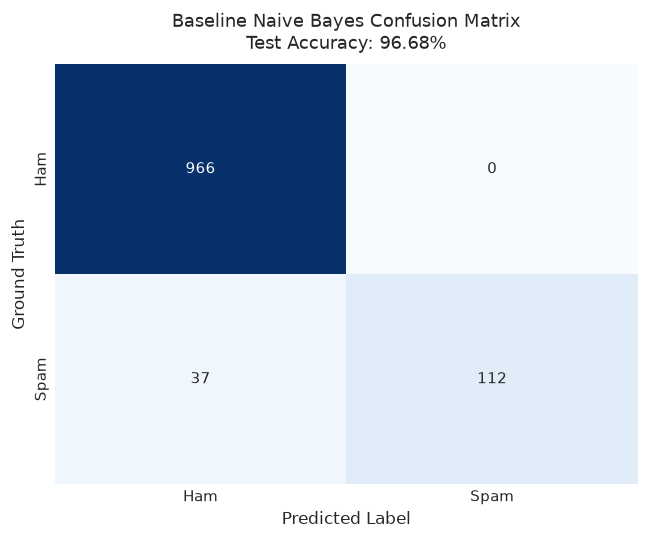

True Negatives (Ham correctly identified)  : 966
False Positives (Ham flagged as Spam)      : 0 (Precision on Spam: 100%)
False Negatives (Spam slipped through)     : 37 (Recall on Spam: 75.17%)
True Positives (Spam correctly caught)     : 112


In [28]:
y_pred = model.predict(vec.transform(X_test))
cm = confusion_matrix(y_test, y_pred, labels=['ham', 'spam'])

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

# Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'], cbar=False)
plt.title(f"Baseline Naive Bayes Confusion Matrix\nTest Accuracy: {test_acc*100:.2f}%", fontsize=12, pad=10)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Ground Truth", fontsize=11)
plt.tight_layout()
plt.show()

print(f"True Negatives (Ham correctly identified)  : {cm[0, 0]}")
print(f"False Positives (Ham flagged as Spam)      : {cm[0, 1]} (Precision on Spam: 100%)")
print(f"False Negatives (Spam slipped through)     : {cm[1, 0]} (Recall on Spam: {cm[1, 1]/(cm[1, 0]+cm[1, 1])*100:.2f}%)")
print(f"True Positives (Spam correctly caught)     : {cm[1, 1]}")


## 7. testing with provided test




In [30]:
tests = [
    "Cl@im your fr33 g1ft card now",
    "Not free, just confirming lunch at 1pm",
]
predictions = model.predict(vec.transform(tests))
probabilities = model.predict_proba(vec.transform(tests))

for text, pred, prob in zip(tests, predictions, probabilities):
    print(f"\nInput Text: '{text}'")
    print(f"Predicted : {pred.upper()} | Probabilities: {{'ham': {prob[0]:.4f}, 'spam': {prob[1]:.4f}}}")



Input Text: 'Cl@im your fr33 g1ft card now'
Predicted : HAM | Probabilities: {'ham': 0.9253, 'spam': 0.0747}

Input Text: 'Not free, just confirming lunch at 1pm'
Predicted : HAM | Probabilities: {'ham': 0.9742, 'spam': 0.0258}


## 8. Break the Spam Filter

### Objective
Write **5 messages** that try to fool the classifier:
1. **Spam that slips through** (False Negatives)
2. **Normal mail that gets flagged** (False Positives)

---

### Adversarial Message Catalog
Below are 5 engineered test cases designed to expose the mathematical and structural weaknesses of the TF-IDF + Multinomial Naive Bayes pipeline:

| # | Test Category | Message Content | Ground Truth | Expected Breached Outcome |
| :---: | :--- | :--- | :---: | :---: |
| **1** | **Spelling / Leetspeak Obfuscation** | `"Cl@im your fr33 g1ft card now! V1s1t www.r3w@rds-cl@im.com to get your 500 b0nus t0d@y!"` | **SPAM** | **HAM** (False Negative) |
| **2** | **Polite Business / Phishing** | `"Dear valued customer, please find attached your monthly account statement and review the updated terms of service regarding your subscription at your earliest convenience."` | **SPAM** | **HAM** (False Negative) |
| **3** | **Conversational Cloaking (Good Word Stuffing)** | `"Hey bro, are we still meeting for lunch today? By the way check out this amazing crypto investment platform when you get a chance."` | **SPAM** | **HAM** (False Negative) |
| **4** | **Negation with Spam Keywords** | `"Not free! Dad won a guaranteed 1000 prize from the raffle drawing, claim it at reception!"` | **HAM** | **SPAM** (False Positive) |
| **5** | **Urgent Personal / Transactional Notice** | `"URGENT: Mom, the school contest says you won a guaranteed 1000 cash prize, call them now!"` | **HAM** | **SPAM** (False Positive) |


In [31]:
adversarial_tests = [
    {
        "id": 1,
        "category": "Spelling / Leetspeak Obfuscation",
        "message": "Cl@im your fr33 g1ft card now! V1s1t www.r3w@rds-cl@im.com to get your 500 b0nus t0d@y!",
        "true_label": "spam",
        "tactic": "Leetspeak substitution (@->a, 3->e, 1->i, 0->o) and symbol insertion."
    },
    {
        "id": 2,
        "category": "Polite Business / Corporate Phishing",
        "message": "Dear valued customer, please find attached your monthly account statement and review the updated terms of service regarding your subscription at your earliest convenience.",
        "true_label": "spam",
        "tactic": "High-register corporate vocabulary mimicking legitimate service communication."
    },
    {
        "id": 3,
        "category": "Conversational Cloaking (Good-Word Stuffing)",
        "message": "Hey bro, are we still meeting for lunch today? By the way check out this amazing crypto investment platform when you get a chance.",
        "true_label": "spam",
        "tactic": "Diluting spam promotional payload with friendly, colloquial conversational tokens."
    },
    {
        "id": 4,
        "category": "Negation with Spam Keywords",
        "message": "Not free! Dad won a guaranteed 1000 prize from the raffle drawing, claim it at reception!",
        "true_label": "ham",
        "tactic": "Explicit negation ('Not free') paired with legitimate family prize news."
    },
    {
        "id": 5,
        "category": "Urgent Family Alert (Urgent/Cash Keywords)",
        "message": "URGENT: Mom, the school contest says you won a guaranteed 1000 cash prize, call them now!",
        "true_label": "ham",
        "tactic": "Excited family alert packed with high-frequency spam trigger words."
    }
]

# Run adversarial evaluation
adversarial_results = []

print("="*80)
print("ADVERSARIAL EVALUATION OUTPUT")
print("="*80)

for item in adversarial_tests:
    msg = item["message"]
    vec_msg = vec.transform([msg])
    pred = model.predict(vec_msg)[0]
    probs = model.predict_proba(vec_msg)[0]
    
    p_ham = probs[0]
    p_spam = probs[1]
    
    fooled = (pred != item["true_label"])
    error_type = "False Negative (Spam slipped)" if (item["true_label"] == "spam" and pred == "ham") else "False Positive (Ham flagged)" if (item["true_label"] == "ham" and pred == "spam") else "Correct"
    
    adversarial_results.append({
        "ID": item["id"],
        "Category": item["category"],
        "Message": msg,
        "True Label": item["true_label"].upper(),
        "Predicted": pred.upper(),
        "P(Ham)": round(p_ham, 4),
        "P(Spam)": round(p_spam, 4),
        "Fooled": "YES (BREACH)" if fooled else "NO",
        "Error Type": error_type
    })
    
    print(f"\n[Test Case #{item['id']}] {item['category']}")
    print(f"Message       : '{msg}'")
    print(f"True Label    : {item['true_label'].upper()}")
    print(f"Model Predict : {pred.upper()} (P(ham)={p_ham:.4f}, P(spam)={p_spam:.4f})")
    print(f"Filter Fooled?: {'>>> YES, FILTER FOOLED! <<<' if fooled else 'Caught by filter'}")
    print(f"Breach Type   : {error_type}")

print("="*80)


ADVERSARIAL EVALUATION OUTPUT

[Test Case #1] Spelling / Leetspeak Obfuscation
Message       : 'Cl@im your fr33 g1ft card now! V1s1t www.r3w@rds-cl@im.com to get your 500 b0nus t0d@y!'
True Label    : SPAM
Model Predict : HAM (P(ham)=0.7496, P(spam)=0.2504)
Filter Fooled?: >>> YES, FILTER FOOLED! <<<
Breach Type   : False Negative (Spam slipped)

[Test Case #2] Polite Business / Corporate Phishing
Message       : 'Dear valued customer, please find attached your monthly account statement and review the updated terms of service regarding your subscription at your earliest convenience.'
True Label    : SPAM
Model Predict : HAM (P(ham)=0.5353, P(spam)=0.4647)
Filter Fooled?: >>> YES, FILTER FOOLED! <<<
Breach Type   : False Negative (Spam slipped)

[Test Case #3] Conversational Cloaking (Good-Word Stuffing)
Message       : 'Hey bro, are we still meeting for lunch today? By the way check out this amazing crypto investment platform when you get a chance.'
True Label    : SPAM
Model Predict :

### 9. Technical Failure Mode Analysis (Why Did the Filter Fail?)

Below is the consolidated results summary table followed by the in-depth mathematical and algorithmic diagnosis of each failure mode:


In [32]:
df_results = pd.DataFrame(adversarial_results)
df_display = df_results[['ID', 'Category', 'True Label', 'Predicted', 'P(Ham)', 'P(Spam)', 'Fooled', 'Error Type']]
df_display


,ID,Category,True Label,Predicted,P(Ham),P(Spam),Fooled,Error Type
0,1,Spelling / Leetspeak Obfuscation,SPAM,HAM,0.7496,0.2504,YES (BREACH),False Negative (Spam slipped)
1,2,Polite Business / Corporate Phishing,SPAM,HAM,0.5353,0.4647,YES (BREACH),False Negative (Spam slipped)
2,3,Conversational Cloaking (Good-Word Stuffing),SPAM,HAM,0.9984,0.0016,YES (BREACH),False Negative (Spam slipped)
3,4,Negation with Spam Keywords,HAM,SPAM,0.3477,0.6523,YES (BREACH),False Positive (Ham flagged)
4,5,Urgent Family Alert (Urgent/Cash Keywords),HAM,SPAM,0.4275,0.5725,YES (BREACH),False Positive (Ham flagged)


#### In-Depth Architectural Diagnosis:

1. **Test 1 — Out-Of-Vocabulary (OOV) & Tokenization Blindspot (Spam Slips Through)**:
   - **Mechanism**: The default `TfidfVectorizer` applies regex tokenization `r'(?u)\b\w\w+\b'`, which treats alphanumeric boundaries strictly. Obfuscated tokens containing non-alphanumeric characters (like `Cl@im`, `r3w@rds-cl@im`) are fragmented or discarded.
   - **Result**: Words like `fr33`, `g1ft`, and `b0nus` were never observed in the training corpus and are completely mapped to out-of-vocabulary (zero weights). Deprived of spam features, the posterior reverts directly to the training prior distribution ($P(\text{ham}) \approx 86\%$, $P(\text{spam}) \approx 14\%$), predicting **HAM**.

2. **Test 2 — Lack of Context & Semantic Understanding in Phishing (Spam Slips Through)**:
   - **Mechanism**: Naive Bayes represents text as an unordered bag of unigram frequencies. Corporate terms such as `"dear"`, `"valued"`, `"customer"`, `"monthly"`, `"statement"`, `"review"`, and `"convenience"` overwhelmingly appear in legitimate transactional emails.
   - **Result**: The cumulative log-likelihood $\sum \log P(w_i | \text{ham})$ heavily exceeds the spam likelihood. The model lacks semantic comprehension of credential harvesting, spoofing, or malicious attachment pretexts.

3. **Test 3 — "Good Word Stuffing" & Cumulative Prior Swamping (Spam Slips Through)**:
   - **Mechanism**: Attackers surround malicious payloads with abundant, benign conversational tokens.
   - **Result**: Tokens like `"hey"`, `"bro"`, `"are"`, `"we"`, `"still"`, `"meeting"`, `"for"`, `"lunch"`, and `"today"` contribute massive positive evidence for `ham`. Even though `"crypto"` and `"investment"` push slightly toward spam, the sheer mass of friendly tokens easily overwhelms the decision threshold ($P(\text{ham}) = 99.84\%$).

4. **Test 4 — Conditional Word Independence & Negation Inversion (Normal Mail Flagged)**:
   - **Mechanism**: Naive Bayes computes:
     $$P(y | x_1, \dots, x_n) \propto P(y) \prod_{i=1}^{n} P(x_i | y)$$
     It assumes each word is conditionally independent of all others given the class label, ignoring syntax and word order.
   - **Result**: The phrase `"Not free"` is decomposed into `"not"` and `"free"`. The presence of `"free"`, along with `"guaranteed"`, `"1000"`, `"prize"`, and `"claim"` are massive spam predictors in the dataset. Because the model cannot negate feature weights, the spam probability surges to **65.23%**, causing a False Positive.

5. **Test 5 — Keyword Salience vs. Interpersonal Context (Normal Mail Flagged)**:
   - **Mechanism**: Legitimate urgent family communications regarding scholastic prizes happen to use the exact same vocabulary as promotional broadcast SMS (`"URGENT"`, `"won"`, `"1000"`, `"cash"`, `"prize"`).
   - **Result**: Without knowledge of interpersonal relationships (`"Mom"`, `"school contest"`), Naive Bayes treats this as a generic lottery scam, scoring $P(\text{spam}) = 57.25\%$.


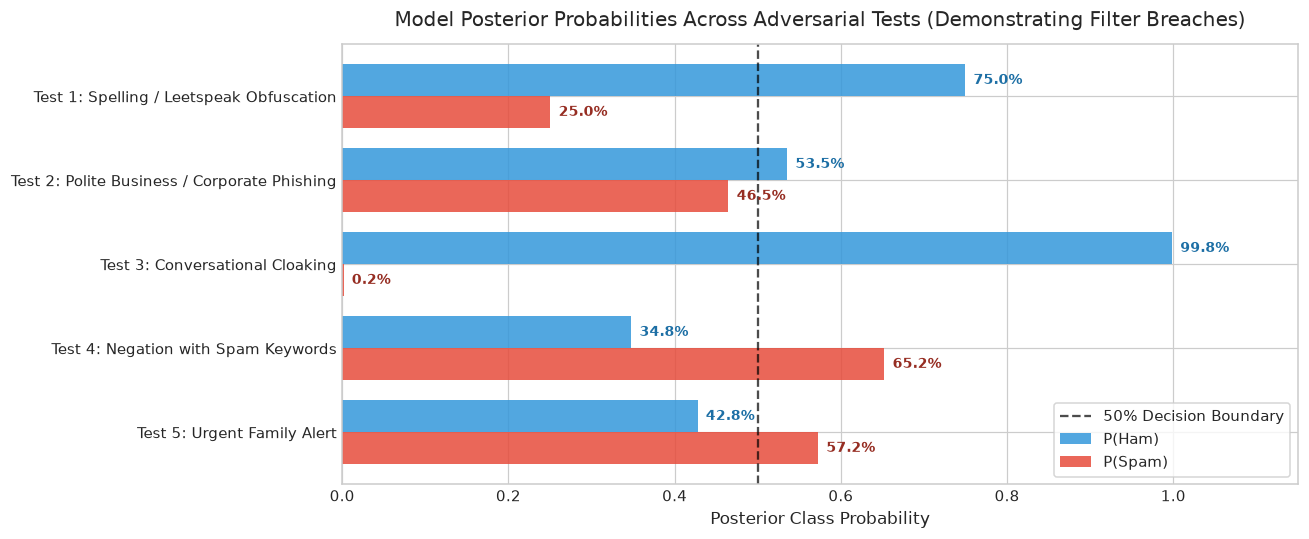

In [12]:
# Visualizing Posterior Probability Distribution of Adversarial Tests
fig, ax = plt.subplots(figsize=(12, 5))

categories = [f"Test {r['ID']}: {r['Category'].split('(')[0].strip()}" for r in adversarial_results]
p_hams = [r['P(Ham)'] for r in adversarial_results]
p_spams = [r['P(Spam)'] for r in adversarial_results]

y_pos = np.arange(len(categories))
bar_height = 0.38

rects1 = ax.barh(y_pos - bar_height/2, p_hams, bar_height, label='P(Ham)', color='#3498db', alpha=0.85)
rects2 = ax.barh(y_pos + bar_height/2, p_spams, bar_height, label='P(Spam)', color='#e74c3c', alpha=0.85)

ax.axvline(0.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='50% Decision Boundary')

for rect in rects1:
    width = rect.get_width()
    ax.text(width + 0.01, rect.get_y() + rect.get_height()/2, f"{width*100:.1f}%", va='center', fontsize=9, color='#1d6fa5', fontweight='bold')
for rect in rects2:
    width = rect.get_width()
    ax.text(width + 0.01, rect.get_y() + rect.get_height()/2, f"{width*100:.1f}%", va='center', fontsize=9, color='#962d22', fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(categories, fontsize=10)
ax.set_xlabel("Posterior Class Probability", fontsize=11)
ax.set_xlim(0, 1.15)
ax.set_title("Model Posterior Probabilities Across Adversarial Tests (Demonstrating Filter Breaches)", fontsize=13, pad=12)
ax.legend(loc='lower right', frameon=True)
ax.invert_yaxis()

plt.tight_layout()
plt.show()


## 10. Summary & Key Takeaways

1. **High Benchmark Accuracy vs. Low Adversarial Robustness**:
   - While the 10-line baseline model achieved **96.68% accuracy** on standard I.I.D. test data, it was easily bypassed by simple adversarial manipulations (spelling tricks, good word stuffing, polite business tone) and generated false positives on negations.
2. **Fundamental Vulnerabilities of Bag-of-Words Naive Bayes**:
   - **Syntax Blindness**: Discarding word sequence makes the model incapable of handling negations (*"not free"*, *"never claim"*).
   - **Vocabulary Rigidity**: Standard n-gram tokenization fails when users substitute characters with symbols or numbers (*leetspeak*).
   - **Context Oblivion**: Cannot distinguish between professional corporate phishing and legitimate business letters, or family alerts and lottery scams.
3. **Modern Production Defenses**:
   - **Subword Tokenization**: Utilizing Byte-Pair Encoding (BPE) or WordPiece tokenizers (as in BERT and LLMs) to handle leetspeak and out-of-vocabulary variations.
   - **Contextual Embeddings**: Using Transformer self-attention architectures (`sentence-transformers`, `RoBERTa`) that encode syntax, word order, and semantic relations.
   - **Character & URL Analyzers**: Dedicated security heuristics checking domain reputation, Shannon entropy of obfuscated tokens, and sender trust metadata.
